# Course 2 — Linear Kalman Filter Deep Dive

*My study notes in simple language. Derivations are only sketched; the focus is on what each idea does and how to use it, with Python demos.*

**Contents**
1. Where the KF equations come from (sequential probabilistic inference)
2. Making the KF robust: numerics, tuning, special noise cases
3. Extra tools: bad-measurement detection, sequential updates, prediction, smoothing, steady-state KF
4. Application: target tracking (polar sensors, IMM, α–β filters)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm, solve_discrete_are
from scipy.stats import chi2

np.random.seed(1)
plt.rcParams["figure.figsize"] = (9, 3.5)
plt.rcParams["axes.grid"] = True

---
## 1. Sequential probabilistic inference

**Goal:** at each time $k$, find the best estimate of $x_k$ given *all* measurements so far, $\mathbb{Z}_k = \{z_0, \dots, z_k\}$.
"Best" here = minimum mean-squared error → the **conditional mean** $\hat x_k^+ = \mathbb{E}[x_k \mid \mathbb{Z}_k]$.

### Predict / correct
- **Predict:** use the model to move the estimate forward: $\hat x_k^- = \mathbb{E}[x_k \mid \mathbb{Z}_{k-1}]$
- **Correct:** use the new measurement: $\hat x_k^+ = \hat x_k^- + L_k\,(z_k - \hat z_k)$

### The gain in general form
$$L_k = \Sigma_{\tilde x \tilde z,k}^-\;\big(\Sigma_{\tilde z,k}\big)^{-1}$$
= (how state error and output error are correlated) × (inverse of output-prediction uncertainty).
- If the prediction error of $z$ is strongly linked to the state error → big correction.
- If the measurement is very uncertain → small correction.

### Six generic steps (valid for *every* KF variant)
| Step | Computes |
|---|---|
| 1a | state prediction $\hat x_k^-$ |
| 1b | prediction-error covariance $\Sigma_{\tilde x,k}^-$ |
| 1c | output prediction $\hat z_k$ |
| 2a | gain $L_k$ (needs $\Sigma_{\tilde z}$ and $\Sigma_{\tilde x\tilde z}$) |
| 2b | state update $\hat x_k^+$ |
| 2c | covariance update $\Sigma_{\tilde x,k}^+ = \Sigma_{\tilde x,k}^- - L_k\Sigma_{\tilde z,k}L_k^T$ |

Linear KF, EKF and SPKF differ **only** in how they compute these expectations.
For a linear model with Gaussian noise, they can be computed exactly and we get the linear KF:
- $\Sigma_{\tilde z} = C\Sigma^-C^T + \Sigma_{\tilde v}$
- $\Sigma_{\tilde x\tilde z} = \Sigma^- C^T$
- so $L = \Sigma^-C^T(C\Sigma^-C^T + \Sigma_{\tilde v})^{-1}$ — same as in Course 1.

In [2]:
# A small reusable linear KF, used throughout this notebook
class LinearKF:
    def __init__(self, A, B, C, D, Q, R, x0, P0, joseph=True):
        self.A, self.B, self.C, self.D, self.Q, self.R = A, B, C, D, Q, R
        self.x, self.P, self.joseph = x0.astype(float).copy(), P0.astype(float).copy(), joseph

    def predict(self, u):
        self.x = self.A @ self.x + self.B @ u                      # 1a
        self.P = self.A @ self.P @ self.A.T + self.Q               # 1b

    def correct(self, z, u, R=None):
        R = self.R if R is None else R
        zhat = self.C @ self.x + self.D @ u                        # 1c
        Sz = self.C @ self.P @ self.C.T + R
        L = self.P @ self.C.T @ np.linalg.inv(Sz)                  # 2a
        r = z - zhat                                               # innovation
        self.x = self.x + L @ r                                    # 2b
        I = np.eye(len(self.x))
        if self.joseph:                                            # 2c (robust form)
            self.P = (I - L @ self.C) @ self.P @ (I - L @ self.C).T + L @ R @ L.T
        else:
            self.P = (I - L @ self.C) @ self.P
        self.P = 0.5 * (self.P + self.P.T)                         # keep symmetric
        return r, Sz

---
## 2. Making the Kalman filter robust

### 2.1 Numerical robustness
With finite-precision arithmetic, $\Sigma_{\tilde x}$ can lose symmetry or even become non-positive-definite → filter blows up. Simple fixes:
1. **Force symmetry** after each update: $\Sigma \leftarrow \tfrac12(\Sigma + \Sigma^T)$
2. **Joseph form** for step 2c (guaranteed positive semi-definite, even with a slightly wrong gain):
$$\Sigma^+ = (I - LC)\Sigma^-(I-LC)^T + L\Sigma_{\tilde v}L^T$$

### 2.2 Square-root Kalman filter
Store the **Cholesky factor** $S$ (with $\Sigma = SS^T$) instead of $\Sigma$.
- $\Sigma$ built from $SS^T$ is always symmetric and positive semi-definite.
- The numbers in $S$ have about half the dynamic range of those in $\Sigma$ → roughly double the precision.
- Updates use QR decompositions instead of plain matrix products. Cost is a bit higher.

In [3]:
def sqrt_kf_step(x, S, z, u, A, B, C, D, Sq, Sr):
    # One square-root KF step. S, Sq, Sr are lower Cholesky factors of P, Q, R.
    n, m = len(x), len(z)
    # predict: [A S, Sq] -> triangularise with QR
    x = A @ x + B @ u
    S = np.linalg.qr(np.hstack([A @ S, Sq]).T, mode="r").T[:, :n]
    # correct: build a pre-array and triangularise
    pre = np.block([[Sr, C @ S], [np.zeros((n, m)), S]])
    post = np.linalg.qr(pre.T, mode="r").T
    Sz, Pxz_Sz_inv, S_new = post[:m, :m], post[m:, :m], post[m:, m:m+n]
    L = Pxz_Sz_inv @ np.linalg.inv(Sz)
    x = x + L @ (z - (C @ x + D @ u))
    return x, S_new

# Quick check against the normal KF on a random system
A = np.array([[1, 0.1], [0, 1]]); B = np.array([[0.005], [0.1]])
Cm = np.array([[1.0, 0]]); Dm = np.zeros((1, 1))
Q = np.diag([1e-4, 1e-3]); R = np.array([[0.05]])
kf = LinearKF(A, B, Cm, Dm, Q, R, np.zeros(2), np.eye(2))
xs, S = np.zeros(2), np.eye(2)
for k in range(50):
    u = np.array([np.sin(k/5)]); z = np.array([np.random.randn()])
    kf.predict(u); kf.correct(z, u)
    xs, S = sqrt_kf_step(xs, S, z, u, A, B, Cm, Dm, np.linalg.cholesky(Q), np.linalg.cholesky(R))
print("max |x diff| :", np.abs(kf.x - xs).max())
print("max |P diff| :", np.abs(kf.P - S @ S.T).max())

max |x diff| : 3.3306690738754696e-16
max |P diff| : 0.0


### 2.3 Initialising and tuning
**Initial state:** use prior knowledge, or compute it from the first few measurements. If unsure, set a **large** $\Sigma_{\tilde x,0}^+$ — the filter then trusts the first measurements more and converges fast. A small covariance with a wrong initial guess causes slow convergence.

**Sensor noise $\Sigma_{\tilde v}$:** from datasheets or by logging the sensor while the true value is constant.

**Process noise $\Sigma_{\tilde w}$:** hardest to know → usually the main tuning knob.
- Too small → filter trusts the model too much, lags or diverges, errors outside bounds.
- Too large → filter follows the noisy measurements, estimates jumpy, bounds too wide.

**How to check tuning (on simulated data):** state errors inside ±3σ bounds ≈ 99.7 % of the time.
**On real data (no truth):** look at the innovations $r_k = z_k - \hat z_k$. They should be zero-mean, white, and the normalised value $r_k^2/\Sigma_{\tilde z,k}$ should average ≈ 1 (per output).

In [4]:
# Innovation check for different process-noise tunings
N = 600; dt = 0.1
A = np.array([[1, dt], [0, 1]]); B = np.zeros((2, 1)); Cm = np.array([[1.0, 0]]); Dm = np.zeros((1, 1))
q_true = 0.5
Q_true = q_true * np.array([[dt**3/3, dt**2/2], [dt**2/2, dt]])
R = np.array([[1.0]])
x = np.zeros((2, N)); z = np.zeros(N)
for k in range(1, N):
    x[:, k] = A @ x[:, k-1] + np.linalg.cholesky(Q_true) @ np.random.randn(2)
for k in range(N):
    z[k] = x[0, k] + np.random.randn()

for scale in [0.01, 1.0, 100.0]:
    kf = LinearKF(A, B, Cm, Dm, Q_true*scale, R, np.zeros(2), np.eye(2)*10)
    nis = []
    for k in range(1, N):
        kf.predict(np.zeros(1)); r, Sz = kf.correct(np.array([z[k]]), np.zeros(1))
        nis.append(float(r @ np.linalg.inv(Sz) @ r))
    print(f"Q scale {scale:>6}: mean normalised innovation² = {np.mean(nis):.2f}  (want ≈ 1)")

Q scale   0.01: mean normalised innovation² = 2.12  (want ≈ 1)
Q scale    1.0: mean normalised innovation² = 1.11  (want ≈ 1)
Q scale  100.0: mean normalised innovation² = 0.94  (want ≈ 1)


**Reading the result:** a value well above 1 means the filter is **overconfident** (Q too small) — easy to detect.
A too-large Q gives a value slightly below 1 and noisy estimates — harder to see, so also check that the innovations look white (no pattern over time).

### 2.4 Non-zero-mean noises
If $w_k$ or $v_k$ have a known mean, just treat the mean as an extra **known input**:
- state: $\hat x_k^- = A\hat x_{k-1}^+ + Bu_{k-1} + \bar w$
- output: $\hat z_k = C\hat x_k^- + Du_k + \bar v$

If the mean (bias) is **unknown**, add it as an extra state (e.g. a random-walk bias) and let the KF estimate it.

### 2.5 Correlated process and sensor noise
If $\mathbb{E}[w_k v_k^T] = \Sigma_{\tilde w\tilde v} \ne 0$, we can remove the correlation with a trick.
Add zero ($T(z_k - Cx_k - Du_k - v_k) = 0$) to the state equation, with $T = \Sigma_{\tilde w\tilde v}\Sigma_{\tilde v}^{-1}$:
$$x_{k+1} = (A - TC)x_k + (B - TD)u_k + T z_k + \underbrace{(w_k - T v_k)}_{\text{new noise}}$$
The new process noise is **uncorrelated** with $v_k$ and has covariance $\Sigma_{\tilde w} - T\Sigma_{\tilde w\tilde v}^T$. Now use the standard KF (the measurement $z_k$ acts like a known input).

### 2.6 Coloured (non-white) noise
KF assumes white noise. If the noise is correlated in time (coloured), model it as the output of a small linear system driven by white noise (**shaping filter**), e.g. $n_{k+1} = \phi\, n_k + e_k$.
Then **augment** the state: $x^{aug} = [x;\ n]$ — now the augmented model has only white noise and the standard KF applies.

---
## 3. Extra tools

### 3.1 Detecting bad measurements (outlier gating)
The innovation $r_k = z_k - \hat z_k$ should be Gaussian with covariance $\Sigma_{\tilde z,k}$.
Compute the **normalised innovation squared**:
$$\text{NIS}_k = r_k^T\,\Sigma_{\tilde z,k}^{-1}\,r_k$$
For a correct measurement it follows a $\chi^2$ distribution with $m$ degrees of freedom ($m$ = number of outputs).
If NIS is larger than a threshold (e.g. the 99.9 % $\chi^2$ value), the measurement is probably a glitch → **skip the correction** for this step (keep only the prediction).

glitches injected: 15 | rejected by gate: 15 | correctly caught: 15


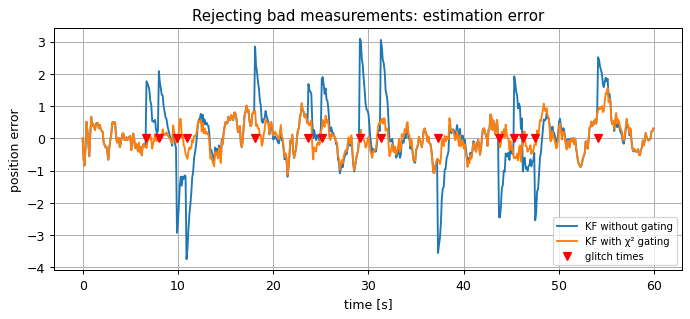

In [5]:
z_bad = z.copy()
idx = np.random.choice(np.arange(50, N), 15, replace=False)
z_bad[idx] += np.random.choice([-1, 1], 15) * np.random.uniform(8, 15, 15)   # inject glitches
thresh = chi2.ppf(0.999, df=1)

def run(gating):
    kf = LinearKF(A, B, Cm, Dm, Q_true, R, np.zeros(2), np.eye(2)*10)
    est = np.zeros(N); rejected = []
    for k in range(1, N):
        kf.predict(np.zeros(1))
        zhat = Cm @ kf.x; Sz = Cm @ kf.P @ Cm.T + R
        r = np.array([z_bad[k]]) - zhat
        if gating and r @ np.linalg.inv(Sz) @ r > thresh:
            rejected.append(k)                     # skip correction
        else:
            kf.correct(np.array([z_bad[k]]), np.zeros(1))
        est[k] = kf.x[0]
    return est, rejected

est_plain, _ = run(False); est_gate, rej = run(True)
t = np.arange(N) * dt
plt.plot(t, est_plain - x[0], label="KF without gating")
plt.plot(t, est_gate - x[0], label="KF with χ² gating")
plt.plot(t[idx], np.zeros(len(idx)), 'rv', label="glitch times")
plt.ylabel("position error"); plt.xlabel("time [s]"); plt.legend(fontsize=8)
plt.title("Rejecting bad measurements: estimation error"); plt.show()
print("glitches injected:", len(idx), "| rejected by gate:", len(rej), "| correctly caught:", len(set(rej) & set(idx)))

### 3.2 Sequential processing of measurements
If the sensor noises are **uncorrelated** ($\Sigma_{\tilde v}$ diagonal), a vector measurement can be processed **one scalar at a time**:
- no matrix inverse — only scalar divisions,
- each sensor can be gated individually,
- sensors that did not report this step are simply skipped.

The result is **identical** to processing all measurements at once. (If $\Sigma_{\tilde v}$ is not diagonal, first decorrelate with its Cholesky factor.)

In [6]:
def correct_sequential(x, P, z, C, Rdiag):
    for i in range(len(z)):
        c = C[i]                                   # one row of C
        s = c @ P @ c + Rdiag[i]                   # scalar
        L = (P @ c) / s                            # gain vector
        x = x + L * (z[i] - c @ x)
        P = P - np.outer(L, c @ P)
    return x, P

# compare with batch update
n, m = 4, 3
P = np.cov(np.random.randn(n, 20)); x0 = np.random.randn(n)
Cmat = np.random.randn(m, n); Rd = np.array([0.5, 1.0, 2.0]); zz = np.random.randn(m)
L = P @ Cmat.T @ np.linalg.inv(Cmat @ P @ Cmat.T + np.diag(Rd))
xb, Pb = x0 + L @ (zz - Cmat @ x0), P - L @ Cmat @ P
xs, Ps = correct_sequential(x0, P, zz, Cmat, Rd)
print("difference in x:", np.abs(xb - xs).max(), " difference in P:", np.abs(Pb - Ps).max())

difference in x: 2.7755575615628914e-16  difference in P: 2.498001805406602e-16


### 3.3 Prediction
To predict the state $j$ steps ahead: just run the **prediction step** (1a, 1b) $j$ times without correction.
The uncertainty grows with every step. This is the same as the open-loop estimate from Course 1.

### 3.4 Smoothing
A **filter** uses measurements up to time $k$. A **smoother** also uses *future* measurements → better estimates, but only offline or with delay.
- *Fixed-point*: improve the estimate at one fixed time.
- *Fixed-lag*: estimate the state $L$ steps in the past (small delay).
- *Fixed-interval*: after collecting all data, improve all estimates.

The **Rauch–Tung–Striebel (RTS)** smoother is the standard fixed-interval smoother: run the KF forward, store $\hat x^\pm, \Sigma^\pm$, then run backward:
$$G_k = \Sigma_k^+ A^T (\Sigma_{k+1}^-)^{-1}$$
$$\hat x_k^s = \hat x_k^+ + G_k(\hat x_{k+1}^s - \hat x_{k+1}^-),\qquad \Sigma_k^s = \Sigma_k^+ + G_k(\Sigma_{k+1}^s - \Sigma_{k+1}^-)G_k^T$$

RMS velocity error  filter: 0.656   smoother: 0.346


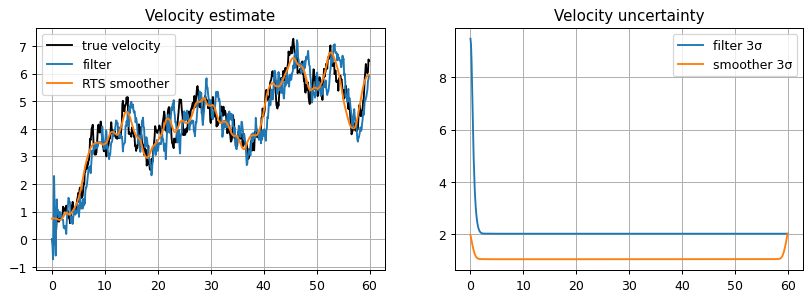

In [7]:
def kf_rts(z, A, C, Q, R, x0, P0):
    N, n = len(z), len(x0)
    xf, Pf = np.zeros((N, n)), np.zeros((N, n, n))      # filtered (+)
    xp, Pp = np.zeros((N, n)), np.zeros((N, n, n))      # predicted (-)
    x, P = x0, P0
    for k in range(N):
        if k > 0:
            x, P = A @ x, A @ P @ A.T + Q
        xp[k], Pp[k] = x, P
        S = C @ P @ C.T + R; L = P @ C.T @ np.linalg.inv(S)
        x = x + L @ (z[k:k+1] - C @ x); P = (np.eye(n) - L @ C) @ P
        xf[k], Pf[k] = x, P
    xs, Ps = xf.copy(), Pf.copy()
    for k in range(N-2, -1, -1):                         # backward pass
        G = Pf[k] @ A.T @ np.linalg.inv(Pp[k+1])
        xs[k] = xf[k] + G @ (xs[k+1] - xp[k+1])
        Ps[k] = Pf[k] + G @ (Ps[k+1] - Pp[k+1]) @ G.T
    return xf, Pf, xs, Ps

xf, Pf, xs, Ps = kf_rts(z, A, Cm, Q_true, R, np.zeros(2), np.eye(2)*10)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(t, x[1], 'k', label="true velocity"); ax[0].plot(t, xf[:, 1], label="filter"); ax[0].plot(t, xs[:, 1], label="RTS smoother")
ax[0].legend(); ax[0].set_title("Velocity estimate")
ax[1].plot(t, 3*np.sqrt(Pf[:, 1, 1]), label="filter 3σ"); ax[1].plot(t, 3*np.sqrt(Ps[:, 1, 1]), label="smoother 3σ")
ax[1].legend(); ax[1].set_title("Velocity uncertainty"); plt.show()
rms = lambda e: np.sqrt(np.mean(e**2))
print("RMS velocity error  filter: %.3f   smoother: %.3f" % (rms(x[1]-xf[:, 1]), rms(x[1]-xs[:, 1])))

### 3.5 Steady-state Kalman filter
For a time-invariant system, $\Sigma_{\tilde x}$ and the gain $L_k$ quickly converge to constants. So we can compute the final gain **offline** and use a fixed gain online:
- much cheaper (no covariance update), good for small microcontrollers,
- slightly worse during the initial transient.

The steady-state prediction covariance solves the **discrete algebraic Riccati equation (DARE)** — in Python: `scipy.linalg.solve_discrete_are(A.T, C.T, Q, R)`.

steady-state gain: [0.1906 0.2012]


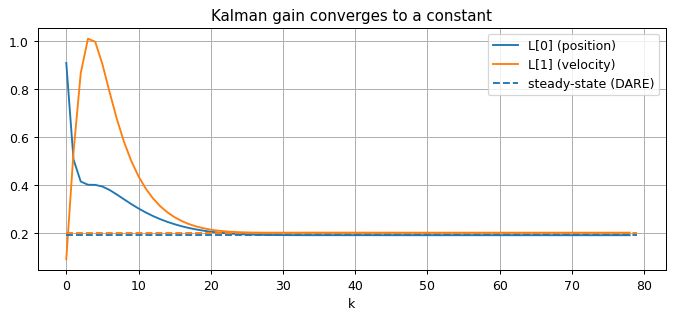

In [8]:
P_ss = solve_discrete_are(A.T, Cm.T, Q_true, R)            # steady-state Σ⁻
L_ss = P_ss @ Cm.T @ np.linalg.inv(Cm @ P_ss @ Cm.T + R)

kf = LinearKF(A, B, Cm, Dm, Q_true, R, np.zeros(2), np.eye(2)*10)
gains = []
for k in range(1, 80):
    kf.predict(np.zeros(1))
    Lk = kf.P @ Cm.T @ np.linalg.inv(Cm @ kf.P @ Cm.T + R); gains.append(Lk.ravel())
    kf.correct(np.array([z[k]]), np.zeros(1))
gains = np.array(gains)
plt.plot(gains[:, 0], label="L[0] (position)"); plt.plot(gains[:, 1], label="L[1] (velocity)")
plt.hlines(L_ss.ravel(), 0, len(gains), colors=['C0', 'C1'], linestyles='--', label="steady-state (DARE)")
plt.xlabel("k"); plt.legend(); plt.title("Kalman gain converges to a constant"); plt.show()
print("steady-state gain:", L_ss.ravel().round(4))

### 3.6 Continuous-time KF (Kalman–Bucy filter)
For a continuous model $\dot x = Ax + Bu + w$, $z = Cx + v$ the filter becomes differential equations:
$$\dot{\hat x} = A\hat x + Bu + L(z - C\hat x),\qquad L = \Sigma C^T\Sigma_{\tilde v}^{-1}$$
$$\dot\Sigma = A\Sigma + \Sigma A^T + \Sigma_{\tilde w} - \Sigma C^T\Sigma_{\tilde v}^{-1}C\Sigma$$
Mostly of theoretical interest today — in practice we use the discrete KF on a computer. Its steady-state version is closely related to the LQR controller (duality).

---
## 4. Application: target tracking

### What makes tracking special
- The target's motion (its "input") is **unknown** → models like NCV treat acceleration as process noise.
- Sensors (radar, sonar) often measure in **polar** coordinates: range $r$ and bearing $\theta$.
- Targets **manoeuvre** — sometimes straight, sometimes turning. One model does not fit all.
- Many targets, clutter, missed detections (data association — not covered here).

### 4.1 Polar measurements with a Cartesian state
State stays Cartesian (NCV). We convert each radar measurement to Cartesian:
$$z^c = \begin{bmatrix} r\cos\theta \\ r\sin\theta\end{bmatrix}$$
and its covariance with the Jacobian $J$ of this conversion:
$$R^c = J\,\text{diag}(\sigma_r^2, \sigma_\theta^2)\,J^T,\quad J = \begin{bmatrix}\cos\theta & -r\sin\theta\\ \sin\theta & r\cos\theta\end{bmatrix}$$
Note: $R^c$ changes each step — far targets have large cross-range uncertainty ($r\sigma_\theta$).

In [9]:
def ncv_model(dt, q):
    # 2-D nearly-constant-velocity model, state = [x, vx, y, vy]
    F1 = np.array([[1, dt], [0, 1]])
    Q1 = q * np.array([[dt**3/3, dt**2/2], [dt**2/2, dt]])
    F = np.kron(np.eye(2), F1); Q = np.kron(np.eye(2), Q1)
    H = np.array([[1, 0, 0, 0], [0, 0, 1, 0]])
    return F, Q, H

# ---- Simulate a target: straight, then a turn, then straight again
dt = 1.0; N = 150
X = np.zeros((4, N)); X[:, 0] = [2000, 15, 5000, 0]
for k in range(1, N):
    omega = np.deg2rad(3.0) if 60 <= k < 90 else 0.0          # coordinated turn in the middle
    c, s = np.cos(omega*dt), np.sin(omega*dt)
    vx, vy = X[1, k-1], X[3, k-1]
    X[1, k], X[3, k] = c*vx - s*vy, s*vx + c*vy
    X[0, k], X[2, k] = X[0, k-1] + X[1, k]*dt, X[2, k-1] + X[3, k]*dt

# ---- Radar at the origin: range and bearing
sig_r, sig_th = 10.0, np.deg2rad(0.5)
rng = np.hypot(X[0], X[2]) + sig_r*np.random.randn(N)
brg = np.arctan2(X[2], X[0]) + sig_th*np.random.randn(N)

def polar_to_cart(r, th):
    z = np.array([r*np.cos(th), r*np.sin(th)])
    J = np.array([[np.cos(th), -r*np.sin(th)], [np.sin(th), r*np.cos(th)]])
    return z, J @ np.diag([sig_r**2, sig_th**2]) @ J.T

print("cross-range σ at 5 km ≈ %.0f m  vs range σ = %.0f m" % (5000*sig_th, sig_r))

cross-range σ at 5 km ≈ 44 m  vs range σ = 10 m


### 4.2 Interacting Multiple Model (IMM) filter
Idea: run **several KFs in parallel**, each with a different motion model (e.g. "quiet" NCV with small $q$ and "manoeuvre" model with large $q$), and blend them.
Each cycle has four parts:
1. **Mixing:** each filter starts from a probability-weighted mix of all filters' previous estimates (the target may have switched model). Switching probabilities are given by a Markov matrix $\Pi$.
2. **Mode-matched filtering:** every KF does a normal predict + correct.
3. **Mode-probability update:** a model whose predicted measurement matched well (high Gaussian likelihood of its innovation) gets a higher probability.
4. **Combination:** output = probability-weighted average of all filters (covariance includes the spread between them).

Result: smooth estimates on straight paths and fast response in turns — without hand-tuning a single compromise $q$.

KF small q : RMS position error = 112.9 m
KF large q : RMS position error = 22.6 m
IMM        : RMS position error = 20.6 m


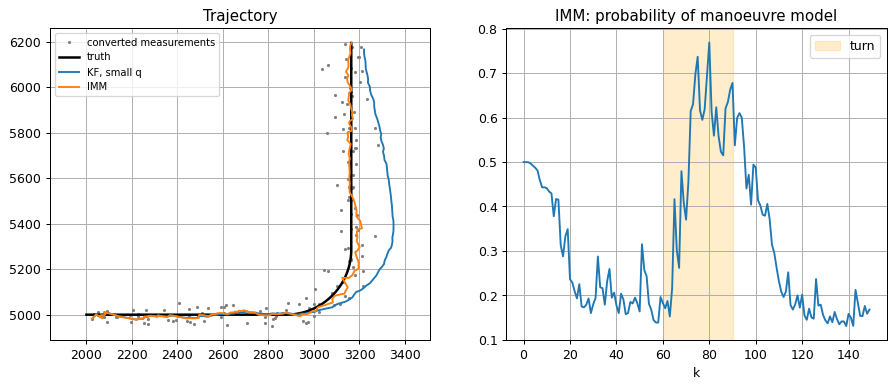

In [10]:
def imm_track(Zc, Rc, models, Pi, mu0, x0, P0):
    M, n, N = len(models), len(x0), Zc.shape[1]
    xs = [x0.copy() for _ in range(M)]; Ps = [P0.copy() for _ in range(M)]
    mu = np.array(mu0, float)
    out, mus = np.zeros((n, N)), np.zeros((M, N))
    for k in range(N):
        # 1) mixing
        cbar = Pi.T @ mu
        w = (Pi * mu[:, None]) / cbar[None, :]           # w[i, j] = P(was i | now j)
        x_mix = [sum(w[i, j]*xs[i] for i in range(M)) for j in range(M)]
        P_mix = [sum(w[i, j]*(Ps[i] + np.outer(xs[i]-x_mix[j], xs[i]-x_mix[j])) for i in range(M)) for j in range(M)]
        # 2) mode-matched KFs  +  3) likelihoods
        lik = np.zeros(M)
        for j, (F, Q, H) in enumerate(models):
            x, P = F @ x_mix[j], F @ P_mix[j] @ F.T + Q
            r = Zc[:, k] - H @ x; S = H @ P @ H.T + Rc[k]
            L = P @ H.T @ np.linalg.inv(S)
            xs[j], Ps[j] = x + L @ r, (np.eye(n) - L @ H) @ P
            lik[j] = np.exp(-0.5 * r @ np.linalg.solve(S, r)) / np.sqrt(np.linalg.det(2*np.pi*S))
        mu = cbar * lik + 1e-300; mu /= mu.sum()
        # 4) combine
        out[:, k] = sum(mu[j]*xs[j] for j in range(M)); mus[:, k] = mu
    return out, mus

Zc, Rc = [], []
for k in range(N):
    zc, R_c = polar_to_cart(rng[k], brg[k]); Zc.append(zc); Rc.append(R_c)
Zc = np.array(Zc).T

x0 = np.array([Zc[0, 0], 0, Zc[1, 0], 0]); P0 = np.diag([100**2, 30**2, 100**2, 30**2])
quiet, manoeuvre = ncv_model(dt, 0.01), ncv_model(dt, 5.0)
Pi = np.array([[0.97, 0.03], [0.03, 0.97]])

est_q, _ = imm_track(Zc, Rc, [quiet], np.array([[1.0]]), [1.0], x0, P0)       # single KF, small q
est_m, _ = imm_track(Zc, Rc, [manoeuvre], np.array([[1.0]]), [1.0], x0, P0)   # single KF, large q
est_imm, mus = imm_track(Zc, Rc, [quiet, manoeuvre], Pi, [0.5, 0.5], x0, P0)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(Zc[0], Zc[1], '.', color='gray', ms=3, label="converted measurements")
ax[0].plot(X[0], X[2], 'k', lw=2, label="truth")
ax[0].plot(est_q[0], est_q[2], label="KF, small q")
ax[0].plot(est_imm[0], est_imm[2], label="IMM")
ax[0].legend(fontsize=8); ax[0].set_title("Trajectory"); ax[0].axis("equal")
ax[1].plot(mus[1]); ax[1].axvspan(60, 90, color='orange', alpha=0.2, label="turn")
ax[1].set_title("IMM: probability of manoeuvre model"); ax[1].set_xlabel("k"); ax[1].legend()
plt.show()

pos_err = lambda e: np.sqrt((e[0]-X[0])**2 + (e[2]-X[2])**2)[10:]
for name, e in [("KF small q", est_q), ("KF large q", est_m), ("IMM", est_imm)]:
    print(f"{name:11s}: RMS position error = {np.sqrt(np.mean(pos_err(e)**2)):.1f} m")

### 4.3 Steady-state α–β (and α–β–γ) filters
For the 1-D NCV model with a position sensor, the steady-state KF gain has only two numbers:
$$\hat x^+ = \hat x^- + \alpha\,(z - \hat x^-),\qquad \hat v^+ = \hat v^- + \frac{\beta}{\Delta t}(z - \hat x^-)$$
This is the classic **α–β tracker**: extremely cheap, used in old radars and still in simple embedded systems.
With an acceleration state (nearly-constant-acceleration model) we get the **α–β–γ** filter.

The optimal α, β depend on one number, the **tracking index** $\lambda = \sigma_w \Delta t^2/\sigma_v$ (manoeuvre noise vs. sensor noise). Below I get them from the DARE.

alpha = 0.191, beta = 0.0201
RMS error  measurement: 1.056   α–β: 0.442


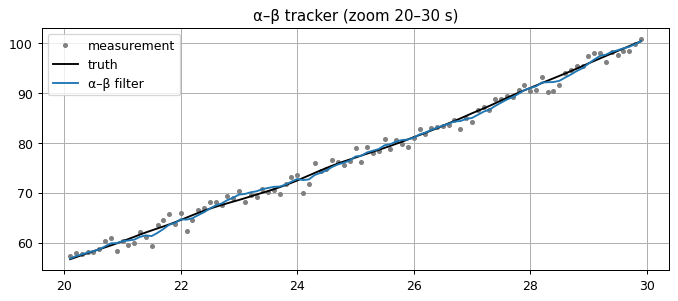

In [11]:
def alpha_beta_from_kf(q, r, dt):
    F = np.array([[1, dt], [0, 1]]); H = np.array([[1.0, 0]])
    Qd = q*np.array([[dt**3/3, dt**2/2], [dt**2/2, dt]])
    P = solve_discrete_are(F.T, H.T, Qd, np.array([[r]]))
    K = P @ H.T / (H @ P @ H.T + r)
    return K[0, 0], K[1, 0]*dt

alpha, beta = alpha_beta_from_kf(q=0.5, r=1.0, dt=0.1)
print(f"alpha = {alpha:.3f}, beta = {beta:.4f}")

# run the α-β filter on the 1-D data from section 2
dt1 = 0.1; xh, vh = 0.0, 0.0; ab = np.zeros(len(z))
for k in range(1, len(z)):
    xp, vp = xh + dt1*vh, vh                  # predict
    r = z[k] - xp                             # innovation
    xh, vh = xp + alpha*r, vp + beta/dt1*r    # fixed-gain correct
    ab[k] = xh
tt = np.arange(len(z))*dt1
w = (tt > 20) & (tt < 30)                     # zoom in to see the difference
plt.plot(tt[w], z[w], '.', color='gray', label="measurement"); plt.plot(tt[w], x[0, w], 'k', label="truth")
plt.plot(tt[w], ab[w], label="α–β filter"); plt.legend(); plt.title("α–β tracker (zoom 20–30 s)"); plt.show()
print("RMS error  measurement: %.3f   α–β: %.3f" % (np.sqrt(np.mean((z-x[0])**2)), np.sqrt(np.mean((ab-x[0])[50:]**2))))

---
## Summary
- All KFs follow the same **six generic steps**; they differ only in how the expectations are computed.
- For robustness: Joseph form, forced symmetry, or square-root KF.
- **Tune** mainly with $\Sigma_{\tilde w}$; check with error bounds (simulation) or normalised innovations (real data).
- Special cases: non-zero-mean noise → known input or bias state; correlated noise → decorrelation trick; coloured noise → state augmentation.
- Useful extras: χ² outlier gating, sequential updates, multi-step prediction, RTS smoothing, fixed-gain steady-state KF.
- Tracking: polar → Cartesian conversion, IMM for manoeuvring targets, α–β filters for cheap tracking.